# Projeto Integrador (P15): Pipeline End-to-End de Engenharia de Dados e ML
## Sentinela Shadow AI: previsão de alertas ignorados no uso de IA generativa em ambiente escolar

**Disciplina:** Banco de Dados para Engenharia de Dados (BDED 2026.1), Especialização em Projetos em IA, UNIFAP Digital
**Docente:** Prof. Dr. Adolfo Francesco de Oliveira Colares
**Autor (equipe individual):** Prof.º Esp. Hernane Bini
**Repositório:** https://github.com/Hbini/sentinela-shadow-ai-pipeline

---
### Problema
Instituições de ensino convivem com a **Shadow AI**: uso de serviços de IA generativa fora da governança institucional.
O *Sentinela* (produto do meu TCC) é uma extensão de navegador que **permite**, **alerta** ou **bloqueia** o acesso a esses serviços.
Quando o usuário recebe um **alerta**, ele pode respeitá-lo (sair) ou **ignorá-lo e prosseguir**.

**Pergunta de ML (classificação binária):** dado um alerta, qual a probabilidade de o usuário ignorá-lo?
Isso permite à gestão **priorizar ações** (treinamento, ajuste de política, comunicação) onde o alerta é menos efetivo.

### Pipeline
```
Fontes (4) -> PostgreSQL (staging -> dw estrela) -> ETL Python -> Features (SQL janela + pandas) -> ML -> Métricas -> Resultados
```

### Fontes de dados
| # | Fonte | Tipo | Acesso |
|---|-------|------|--------|
| 1 | Logs de eventos da extensão Sentinela + cadastros pseudonimizados | JSONL / CSV | simulados com semente fixa (ver nota) |
| 2 | Feriados nacionais | API REST pública **BrasilAPI** | `GET /api/feriados/v1/2026` |
| 3 | Catálogo público de domínios de IA | Repositório **GitHub** `abixb/llm-hosts-blocklist` | API do GitHub + raw |
| 4 | Calendário acadêmico 2026.1 | CSV institucional | `data/raw/calendario_academico_2026.csv` |

> **Nota de transparência:** o Sentinela está em piloto, sem volume real de eventos, e registros reais de estudantes exigiriam consentimento e base legal (LGPD). Por isso a fonte 1 é **simulada** com o mesmo esquema da extensão v0.2, usando as fontes reais 2 e 4 para modular volume e comportamento. As fontes 2 e 3 são coletadas da internet; se estiverem indisponíveis, o pipeline usa snapshots versionados em `data/cache/` e registra a origem usada.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from src import config

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 40)
engine = create_engine(config.pg_url())
def q(sql):
    with engine.connect() as c:
        return pd.read_sql(sql, c)
print("Conectado a", config.PG_DB, "em", config.PG_HOST)

Conectado a sentinela_dw em localhost


## 1. Coleta + ETL em Python -> PostgreSQL
Cria o banco `sentinela_dw`, os esquemas `staging` e `dw` (`sql/01_schema.sql`), extrai as 4 fontes, carrega os dados brutos em `staging`, transforma em pandas e carrega o modelo estrela; por fim cria as views (`sql/02_views.sql`).

In [2]:
import logging
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True)
from src.etl import pipeline_etl
qualidade = pipeline_etl.executar(regerar_logs=True)

INFO src.etl.pipeline_etl: SQL executado: 01_schema.sql


INFO src.extract.coletar_feriados: Feriados coletados: 14 (origem=brasilapi)


INFO src.extract.coletar_catalogo_ia: Catalogo externo: 235 dominios (origem=github:abixb/llm-hosts-blocklist)


INFO src.extract.gerar_eventos_sentinela: Eventos gerados: 50713 (com duplicatas), usuarios: 658, estacoes: 120


INFO src.etl.pipeline_etl: staging.stg_eventos: 50713 linhas


...

INFO src.etl.pipeline_etl: staging.stg_feriados: 14 linhas


INFO src.etl.pipeline_etl: staging.stg_calendario: 10 linhas


INFO src.etl.pipeline_etl: dw carregado: fato=49196 linhas


INFO src.etl.pipeline_etl: SQL executado: 02_views.sql


INFO src.etl.pipeline_etl: Relatorio de qualidade: {'usuarios_brutos': 658, 'usuarios_duplicados_removidos': 8, 'categorias_padronizadas': 3, 'servicos_no_catalogo_externo': 17, 'tamanho_catalogo_externo': 235, 'eventos_brutos': 50713, 'eventos_duplicados_removidos': 1477, 'dominios_normalizados': 2429, 'exposicao_nula_imputada': 483, 'eventos_quarentena': 40, 'eventos_carregados': 49196, 'alertas_warn': 40870, 'taxa_prosseguiu': 0.4762, 'fontes': {'feriados': 'brasilapi', 'catalogo_externo': 'github:abixb/llm-hosts-blocklist', 'calendario': 'data/raw/calendario_academico_2026.csv', 'eventos': 'data/raw/sentinela_eventos.jsonl (simulado, semente 42)'}, 'contagens_dw': {'dim_data': 149, 'dim_usuario': 650, 'dim_estacao': 120, 'dim_servico': 42, 'fato_evento_acesso': 49196, 'quarentena_eventos': 40, 'vw_base_alertas': 40870}, 'executado_em': '2026-10-04 13:11:11'}


### 1.1 Relatório de qualidade de dados (transformações do ETL)

In [3]:
pd.DataFrame({
    "verificacao": ["usuarios duplicados removidos", "categorias padronizadas", "eventos brutos",
                    "eventos duplicados (fila de reenvio) removidos", "dominios normalizados (www/maiusculas)",
                    "exposicao nula imputada", "eventos em quarentena (chave orfa)", "eventos carregados no fato"],
    "valor": [qualidade[k] for k in ["usuarios_duplicados_removidos", "categorias_padronizadas", "eventos_brutos",
              "eventos_duplicados_removidos", "dominios_normalizados", "exposicao_nula_imputada",
              "eventos_quarentena", "eventos_carregados"]]})

,verificacao,valor
0,usuarios duplicados removidos,8
1,categorias padronizadas,3
2,eventos brutos,50713
3,eventos duplicados (fila de reenvio) removidos,1477
4,dominios normalizados (www/maiusculas),2429
5,exposicao nula imputada,483
6,eventos em quarentena (chave orfa),40
7,eventos carregados no fato,49196


In [4]:
print("Origem efetiva das fontes externas:")
for k, v in qualidade["fontes"].items(): print(f"  {k:18s} {v}")
pd.Series(qualidade["contagens_dw"], name="linhas").to_frame()

Origem efetiva das fontes externas:
  feriados           brasilapi
  catalogo_externo   github:abixb/llm-hosts-blocklist
  calendario         data/raw/calendario_academico_2026.csv
  eventos            data/raw/sentinela_eventos.jsonl (simulado, semente 42)


,linhas
dim_data,149
dim_usuario,650
dim_estacao,120
dim_servico,42
fato_evento_acesso,49196
quarentena_eventos,40
vw_base_alertas,40870


### 1.2 Modelagem no PostgreSQL (esquema estrela)
```
                 dim_data (calendário + feriados)
                         |
dim_usuario --- fato_evento_acesso --- dim_servico (política interna + catálogo GitHub)
                         |
                    dim_estacao
```
* **Grão do fato:** um evento de acesso a serviço de IA detectado pela extensão.
* Chaves substitutas (`SERIAL`), integridade referencial (FK), `CHECK` de domínio e `UNIQUE` nas chaves naturais.
* Registros com chaves órfãs vão para `dw.quarentena_eventos` (rastreabilidade).

In [5]:
q('''SELECT table_schema, table_name, table_type FROM information_schema.tables
WHERE table_schema IN ('staging','dw') ORDER BY 1, 3, 2''')

,table_schema,table_name,table_type
0,dw,dim_data,BASE TABLE
1,dw,dim_estacao,BASE TABLE
2,dw,dim_servico,BASE TABLE
3,dw,dim_usuario,BASE TABLE
4,dw,fato_evento_acesso,BASE TABLE
5,dw,quarentena_eventos,BASE TABLE
6,dw,vw_base_alertas,VIEW
7,dw,vw_painel_diario,VIEW
8,dw,vw_ranking_servicos,VIEW
9,staging,stg_calendario,BASE TABLE


## 2. Análise exploratória (resumo; detalhes em `01_analise_exploratoria.ipynb`)

Alertas (linhas da base de ML): 40870 | taxa de ignorados: 0.476


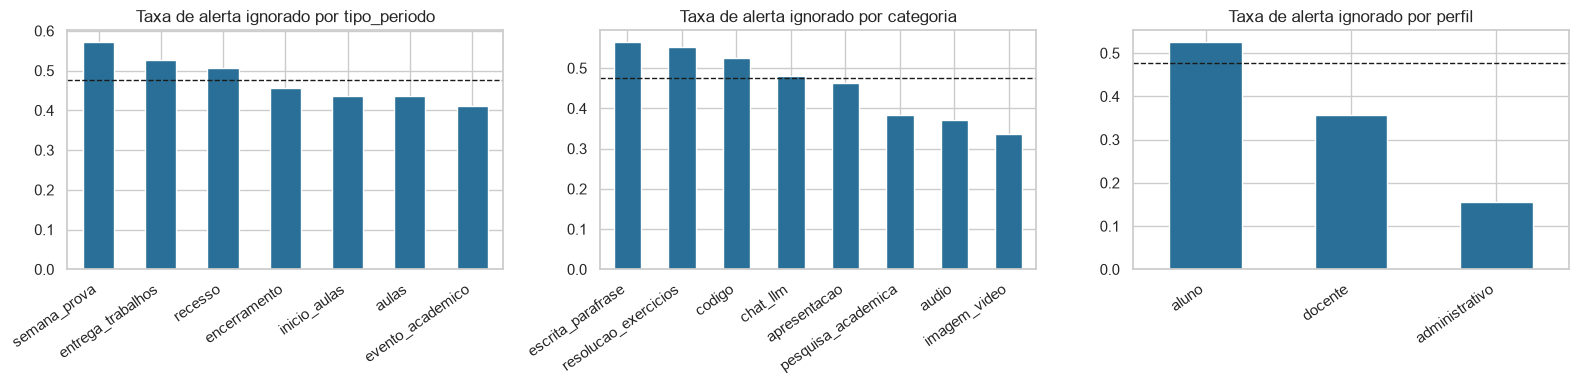

In [6]:
base_sql = q("SELECT * FROM dw.vw_base_alertas")
print("Alertas (linhas da base de ML):", len(base_sql), "| taxa de ignorados:", round(base_sql.alvo_prosseguiu.mean(), 3))
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for col, ax in zip(["tipo_periodo", "categoria", "perfil"], axs):
    t = base_sql.groupby(col)["alvo_prosseguiu"].mean().sort_values(ascending=False)
    t.plot.bar(ax=ax, color="#2a6f97"); ax.axhline(base_sql.alvo_prosseguiu.mean(), ls="--", c="k", lw=1)
    ax.set_title(f"Taxa de alerta ignorado por {col}"); ax.set_xlabel(""); plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
plt.tight_layout(); plt.show()

In [7]:
q('''SELECT perfil, treinado_ia, COUNT(*) alertas, ROUND(AVG(alvo_prosseguiu)::numeric,3) taxa_ignorou
FROM dw.vw_base_alertas GROUP BY 1,2 ORDER BY 1,2''')

,perfil,treinado_ia,alertas,taxa_ignorou
0,administrativo,False,2402,0.182
1,administrativo,True,1123,0.097
2,aluno,False,24537,0.563
3,aluno,True,8516,0.420
4,docente,False,3594,0.376
5,docente,True,698,0.254


## 3. Preparação dos dados e engenharia de features
Parte das features é calculada **no PostgreSQL** (view `dw.vw_base_alertas`) com funções de janela
(`ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING`), usando apenas eventos **anteriores** ao alerta.
O restante é feito em pandas (`src/features/build_features.py`).

| Grupo | Features |
|-------|----------|
| Tempo | `hora_sin`, `hora_cos` (codificação cíclica), `noturno`, `dia_semana`, `semana_letiva` |
| Calendário (fontes 2 e 4) | `semana_prova`, `entrega_trabalhos`, `feriado` |
| Usuário | `perfil`, `curso`, `area_ti`, `semestre_num`, `calouro`, `turno`, `treinado_ia` (na data do evento) |
| Contexto | `local` da estação, `exposicao` de contexto, `navegador` |
| Serviço (fonte 3) | `categoria`, `catalogado_interno`, `no_catalogo_externo` |
| Histórico (SQL janela) | `taxa_ignorar_hist` (suavização de Laplace), `n_alertas_hist`, `log_eventos_hist`, `taxa_bloqueio_hist`, `sem_historico` |
| Fadiga de alerta | `alertas_previos_dia`, `log_alertas_previos_dia` |

**Excluídas de propósito:** `evento_id` (identificador), `dominio` (alta cardinalidade; coberto por `categoria`) e **`tempo_decisao_ms` (vazamento: só existe depois da decisão)**.

In [8]:
from src.features import build_features
base = build_features.executar()
print(base.shape)
base.head()

INFO src.features.build_features: Base de alertas lida do PostgreSQL: (40870, 30)


INFO src.features.build_features: Features salvas em C:\Users\ACER\OneDrive\Escola\03. Pós Graduação\2026\Projetos em Inteligencia Artificial\01. Matérias\06. Banco de Dados para Engenharia de Dados\Tabalho final\sentinela-shadow-ai-pipeline\data\processed\base_modelo.csv: (40870, 34)


(40870, 34)


,evento_id,ts_local,data,dominio,tempo_decisao_ms,hora_sin,hora_cos,dia_semana,semana_letiva,semestre_num,alertas_previos_dia,log_alertas_previos_dia,n_alertas_hist,log_eventos_hist,taxa_ignorar_hist,taxa_bloqueio_hist,noturno,calouro,semana_prova,entrega_trabalhos,feriado,area_ti,treinado_ia,catalogado_interno,no_catalogo_externo,sem_historico,perfil,turno,local,categoria,exposicao,navegador,curso,alvo_prosseguiu
0,183be8f2-2569-2adf-1d77-90d88fff16ba,2026-02-02 07:02:27,2026-02-02,meta.ai,4511,0.965926,-0.258819,0,1,0,0,0.0,0,0.0,0.5,0.0,0,0,0,0,0,0,0,1,1,1,administrativo,manha,administrativo,chat_llm,nenhuma,chrome,nao_se_aplica,0
1,1073e479-e359-1936-0469-30943d44209f,2026-02-02 07:13:47,2026-02-02,chat.openai.com,1067,0.965926,-0.258819,0,1,9,0,0.0,0,0.0,0.5,0.0,0,0,0,0,0,1,1,1,1,1,aluno,manha,biblioteca,chat_llm,nenhuma,chrome,Engenharia,1
2,2dcc3f58-5729-0ddc-6e15-4262a2212716,2026-02-02 07:19:37,2026-02-02,chat.deepseek.com,3450,0.965926,-0.258819,0,1,7,0,0.0,0,0.0,0.5,0.0,0,0,0,0,0,1,0,1,1,1,aluno,manha,laboratorio,chat_llm,contexto_alto,edge,Ciencia da Computacao,1
3,44637ad3-429d-b0e3-1428-660df724fa11,2026-02-02 07:31:26,2026-02-02,kimi.com,4374,0.965926,-0.258819,0,1,0,0,0.0,0,0.0,0.5,0.0,0,0,0,0,0,1,0,0,0,1,docente,noite,sala_docentes,chat_llm,contexto_alto,chrome,Engenharia,0
4,3f38ce8a-e015-f175-4f27-cfa34a949cfa,2026-02-02 07:43:37,2026-02-02,grok.com,3503,0.965926,-0.258819,0,1,0,0,0.0,0,0.0,0.5,0.0,0,0,0,0,0,0,0,0,0,1,administrativo,noite,administrativo,chat_llm,contexto_baixo,chrome,nao_se_aplica,0


In [9]:
from src.features.build_features import NUMERICAS, BINARIAS, CATEGORICAS, EXCLUIDAS
print(f"{len(NUMERICAS)} numericas, {len(BINARIAS)} binarias, {len(CATEGORICAS)} categoricas")
pd.Series(EXCLUIDAS, name="motivo da exclusao").to_frame()

11 numericas, 10 binarias, 7 categoricas


,motivo da exclusao
evento_id,identificador
ts_local,usado apenas para o split temporal
dominio,alta cardinalidade; representado por categoria
tempo_decisao_ms,VAZAMENTO: medido depois da decisao (alvo)
n_ignorados_hist,substituida pela taxa suavizada


In [10]:
base[NUMERICAS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
hora_sin,40870.0,-0.470,0.616,-1.000,-0.966,-0.707,-0.259,0.966
hora_cos,40870.0,-0.050,0.631,-1.000,-0.707,-0.000,0.500,0.866
dia_semana,40870.0,2.148,1.549,0.000,1.000,2.000,3.000,5.000
semana_letiva,40870.0,11.846,6.067,1.000,7.000,11.000,17.000,22.000
semestre_num,40870.0,4.290,3.335,0.000,1.000,4.000,7.000,10.000
alertas_previos_dia,40870.0,0.464,0.839,0.000,0.000,0.000,1.000,11.000
log_alertas_previos_dia,40870.0,0.271,0.429,0.000,0.000,0.000,0.693,2.485
n_alertas_hist,40870.0,47.666,44.263,0.000,16.000,35.000,66.000,369.000
log_eventos_hist,40870.0,3.601,1.102,0.000,2.996,3.784,4.382,6.091
taxa_ignorar_hist,40870.0,0.465,0.204,0.013,0.316,0.471,0.619,0.952


## 4. Treinamento do modelo
* **Split temporal:** treino = fev a mai/2026; teste = jun/2026 (simula o uso em produção, sem embaralhar o tempo).
* **Seleção do modelo:** validação cruzada `TimeSeriesSplit` (5 dobras) no treino, métrica ROC-AUC.
* **Candidatos:** baseline (classe majoritária), Regressão Logística, Random Forest e Gradient Boosting (HistGB), todos em `Pipeline` com `ColumnTransformer` (padronização + one-hot), evitando vazamento de pré-processamento.

In [11]:
from src.models import train
resultado = train.executar(base)
print("Modelo escolhido:", resultado["modelo_escolhido"])
print("Split:", resultado["split"])

INFO src.models.train: Treino (31360, 28) (46.3% positivos) | Teste (9510, 28) (51.9% positivos)


INFO src.models.train: CV Baseline (classe majoritaria)  AUC=0.5000 F1=0.0000


INFO src.models.train: CV Regressao Logistica            AUC=0.7401 F1=0.6340


INFO src.models.train: CV Random Forest                  AUC=0.7289 F1=0.6166


INFO src.models.train: CV Gradient Boosting (HistGB)     AUC=0.7265 F1=0.6277


INFO src.models.train: Modelo escolhido: Regressao Logistica


INFO src.models.train: Teste (Regressao Logistica): {'accuracy': 0.6952, 'precision': 0.7025, 'recall': 0.7152, 'f1': 0.7088, 'roc_auc': 0.7626, 'pr_auc': 0.7604, 'brier': 0.1978}


Modelo escolhido: Regressao Logistica
Split: {'treino': ['2026-02-02', '2026-05-30'], 'teste': ['2026-06-01', '2026-06-30'], 'n_treino': 31360, 'n_teste': 9510, 'taxa_positiva_treino': 0.463265306122449, 'taxa_positiva_teste': 0.5187171398527866}


In [12]:
cv = pd.DataFrame(resultado["validacao_cruzada"]).T[["roc_auc", "roc_auc_std", "f1", "accuracy"]]
cv.columns = ["ROC-AUC (CV)", "desvio", "F1 (CV)", "Accuracy (CV)"]
cv.round(4)

,ROC-AUC (CV),desvio,F1 (CV),Accuracy (CV)
Baseline (classe majoritaria),0.5000,0.0000,0.0000,0.5342
Regressao Logistica,0.7401,0.0131,0.6340,0.6728
Random Forest,0.7289,0.0153,0.6166,0.6667
Gradient Boosting (HistGB),0.7265,0.0182,0.6277,0.6636


## 5. Avaliação no conjunto de teste (junho/2026)

In [13]:
teste = pd.DataFrame(resultado["teste"]).T
teste.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "Brier"]
teste.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier
Baseline (classe majoritaria),0.4813,0.0000,0.0000,0.0000,0.5000,0.5187,0.5187
Regressao Logistica,0.6952,0.7025,0.7152,0.7088,0.7626,0.7604,0.1978
Random Forest,0.6850,0.7026,0.6809,0.6916,0.7516,0.7486,0.2050
Gradient Boosting (HistGB),0.6906,0.6962,0.7162,0.7060,0.7590,0.7558,0.1992


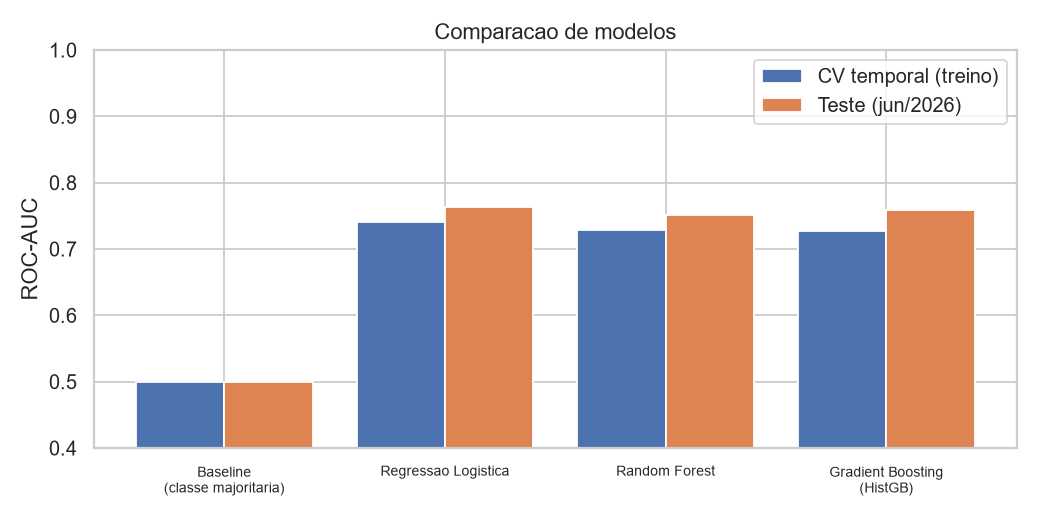

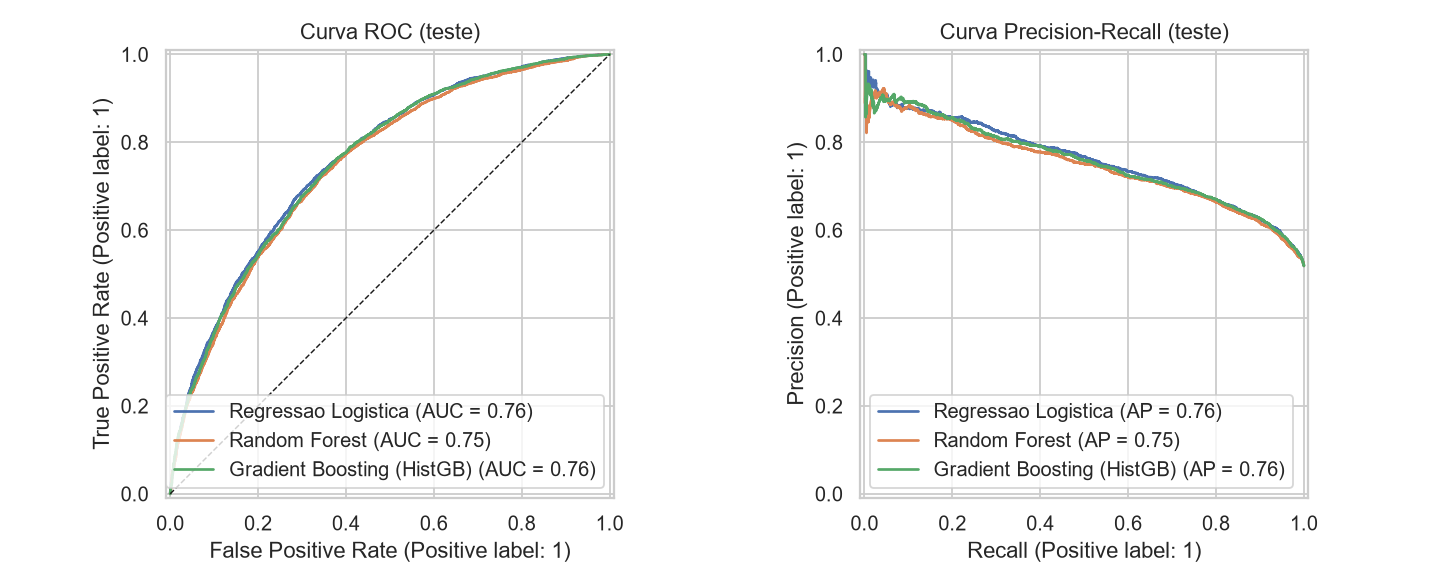

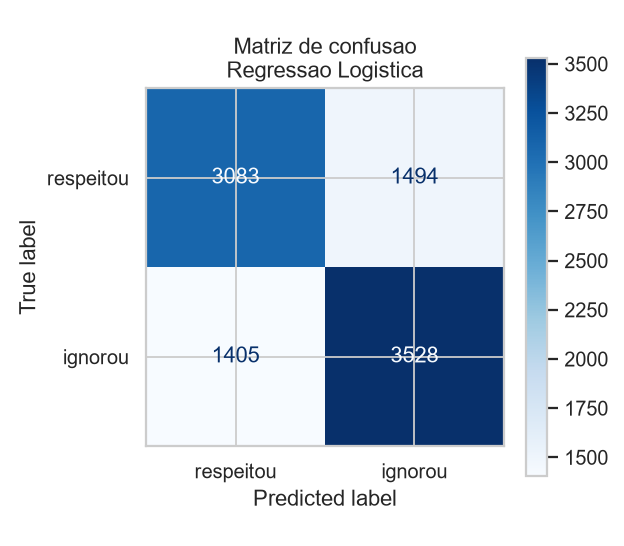

In [14]:
from IPython.display import Image, display
for f in ["comparacao_modelos.png", "curvas_roc_pr.png", "matriz_confusao.png"]:
    display(Image(filename=str(config.FIGS / f)))

## 6. Interpretação: o que explica o alerta ignorado?

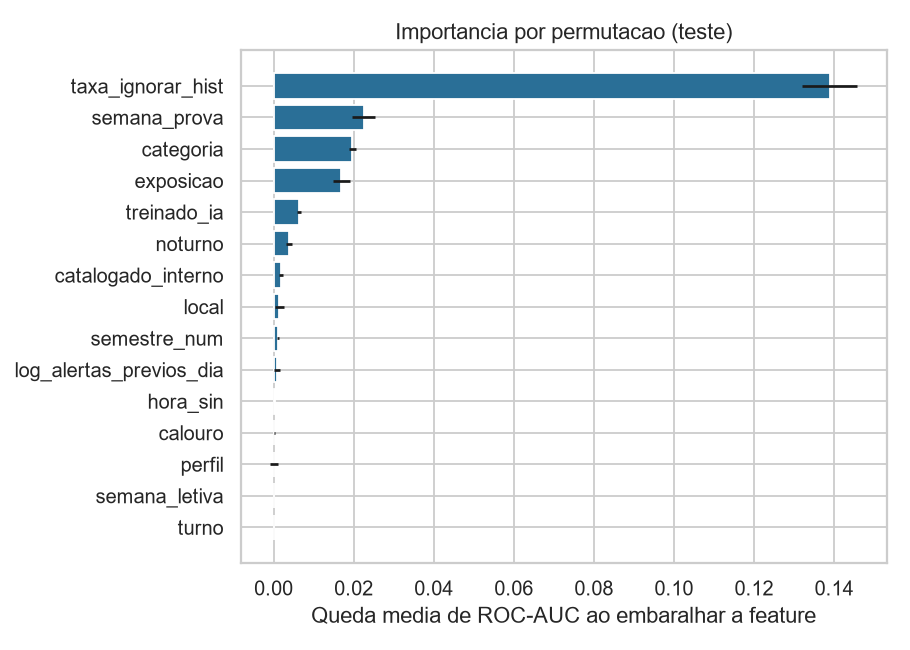

,feature,queda_auc,desvio
0,taxa_ignorar_hist,0.1389,0.0069
1,semana_prova,0.0225,0.0029
2,categoria,0.0197,0.0009
3,exposicao,0.0169,0.0021
4,treinado_ia,0.0064,0.0004
5,noturno,0.0039,0.0008
6,catalogado_interno,0.0019,0.0005
7,local,0.0014,0.0011
8,semestre_num,0.0012,0.0003
9,log_alertas_previos_dia,0.0008,0.0007


In [15]:
display(Image(filename=str(config.FIGS / "importancia_features.png")))
pd.DataFrame(resultado["importancia_permutacao_top10"]).round(4)

In [16]:
import joblib
modelo = joblib.load(config.MODELS / "modelo_sentinela.joblib")
if hasattr(modelo.named_steps["clf"], "coef_"):
    nomes = modelo.named_steps["prep"].get_feature_names_out()
    coef = pd.Series(modelo.named_steps["clf"].coef_[0], index=nomes).sort_values()
    coef = pd.concat([coef.head(8), coef.tail(8)])
    ax = coef.plot.barh(figsize=(8, 6), color=np.where(coef > 0, "#d62728", "#2a6f97"))
    ax.set_title("Coeficientes da Regressão Logística (vermelho aumenta a chance de ignorar)")
    plt.tight_layout(); plt.show()

## 7. Uso prático: priorização por decil de risco

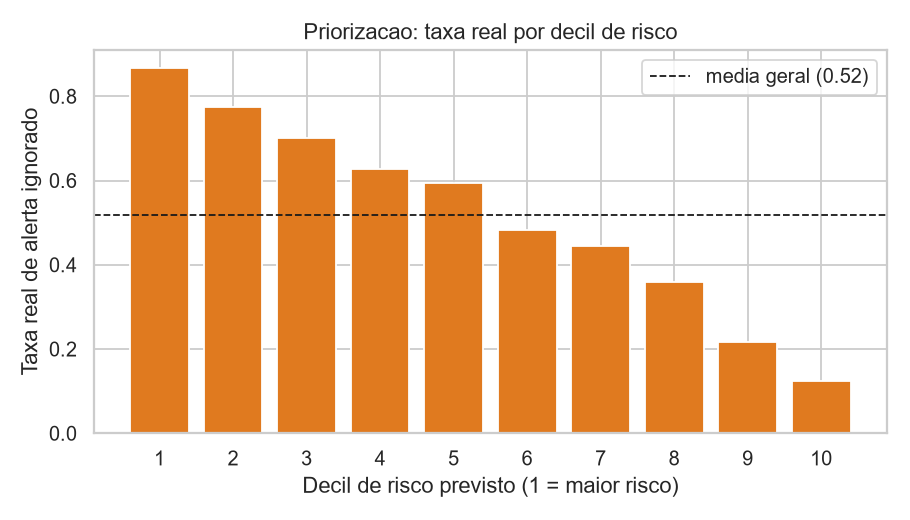

Nos 20% de alertas com maior risco previsto, a taxa real de alerta ignorado foi 82.1% (media do teste: 51.9%).


,decil,alertas,taxa_real,prob_media
0,1,951,0.866,0.841
1,2,951,0.775,0.756
2,3,951,0.701,0.688
3,4,951,0.627,0.620
4,5,951,0.593,0.553
5,6,951,0.482,0.485
6,7,951,0.444,0.414
7,8,951,0.359,0.336
8,9,951,0.218,0.246
9,10,951,0.123,0.127


In [17]:
display(Image(filename=str(config.FIGS / "lift_decis.png")))
lift = pd.DataFrame(resultado["lift_por_decil"]).round(3)
print(f"Nos 20% de alertas com maior risco previsto, a taxa real de alerta ignorado foi "
      f"{resultado['taxa_real_top20pct_risco']:.1%} (media do teste: {resultado['split']['taxa_positiva_teste']:.1%}).")
lift

## 8. Controle de vazamento (*data leakage*)

In [18]:
vz = pd.DataFrame(resultado["controle_vazamento"]).T[["roc_auc", "f1", "accuracy"]]
vz.round(4)

,roc_auc,f1,accuracy
com_tempo_decisao_ms,0.8891,0.8224,0.8076
sem (modelo final),0.7626,0.7088,0.6952


O modelo com `tempo_decisao_ms` parece muito melhor, mas essa variável **só é conhecida depois que o usuário decide**: em produção, no momento do alerta, ela não existe. O ganho é ilusório e por isso a variável foi excluída. As features históricas também foram construídas com janela que termina no evento **anterior**, e o teste é cronologicamente posterior ao treino.

## 9. Exemplo de inferência (como o n8n/Sentinela usaria o modelo)

In [19]:
from src.models.train import FEATURES
exemplo = base[base.ts_local >= config.DATA_CORTE_TESTE].sample(5, random_state=1)
saida = exemplo[["perfil", "categoria", "exposicao", "semana_prova", "treinado_ia", "taxa_ignorar_hist"]].copy()
saida["prob_ignorar"] = modelo.predict_proba(exemplo[FEATURES])[:, 1].round(3)
saida["prioridade"] = pd.cut(saida.prob_ignorar, [0, .4, .65, 1], labels=["baixa", "media", "alta"])
saida["real"] = exemplo["alvo_prosseguiu"].values
saida

,perfil,categoria,exposicao,semana_prova,treinado_ia,taxa_ignorar_hist,prob_ignorar,prioridade,real
36996,aluno,escrita_parafrase,contexto_baixo,0,1,0.388889,0.414,media,1
38712,aluno,chat_llm,contexto_alto,1,0,0.553719,0.552,media,1
40826,aluno,escrita_parafrase,nenhuma,0,1,0.367188,0.424,media,0
37682,administrativo,chat_llm,contexto_baixo,1,0,0.294118,0.296,baixa,0
38809,docente,resolucao_exercicios,contexto_baixo,1,0,0.344828,0.460,media,1


## 10. Resultados e conclusões
* **Pipeline completo e reprodutível:** 4 fontes -> `staging` -> modelo estrela `dw` -> views com features em SQL -> features em pandas -> 4 modelos -> métricas e figuras, com um único comando (`python run_pipeline.py`).
* **Modelo final:** a **Regressão Logística** venceu na validação cruzada temporal e manteve o desempenho no teste de junho (ROC-AUC de 0,763 e F1 de 0,709, contra 0,50 / 0,00 do baseline). Os modelos de árvore não superaram o linear: os efeitos são em grande parte aditivos, e um modelo simples é preferível por ser interpretável e barato (roda em CPU, requisito do Sentinela).
* **Valor prático:** o decil de maior risco concentra cerca de 82% de alertas ignorados, contra cerca de 52% na média. A gestão pode focar treinamento e comunicação nesse grupo.
* **Fatores principais:** histórico do usuário, semana de provas, categoria do serviço (paráfrase e resolução de exercícios), exposição de contexto e **treinamento em IA** (efeito protetor), o que dá suporte a ações de letramento em IA.
* **Integração com o TCC:** o modelo pode virar a camada preditiva do Sentinela no n8n, devolvendo a probabilidade e a prioridade, com o gestor no circuito (*human-in-the-loop*).

### Limitações
* A fonte 1 é **simulada**: as relações aprendidas refletem as hipóteses usadas na simulação. O próximo passo é retreinar com os logs reais do piloto, com consentimento e base legal (LGPD).
* As features de histórico favorecem usuários com mais eventos; para usuários novos (`sem_historico = 1`) o modelo depende só do contexto.
* Limiar fixo em 0,5; em produção o limiar deve seguir o custo de cada ação da gestão.

### Referências
* BRASILAPI. *Feriados nacionais*. Disponível em: https://brasilapi.com.br/docs#tag/Feriados-Nacionais.
* ABIXB. *llm-hosts-blocklist*. GitHub. Disponível em: https://github.com/abixb/llm-hosts-blocklist.
* PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. *JMLR*, v. 12, p. 2825-2830, 2011.
* KIMBALL, R.; ROSS, M. *The Data Warehouse Toolkit*. 3. ed. Wiley, 2013.
* NIST. *AI Risk Management Framework (AI RMF 1.0)*. 2023.
* BRASIL. Lei nº 13.709/2018 (LGPD).
* Nota de transparência: este trabalho contou com o auxílio da ferramenta de IA **Claude (Anthropic)** na estruturação do código, da documentação e da análise; todas as decisões, execuções e revisões foram feitas pelo autor.